# 5-ESC — Environmental Sound Classification (ESC)
### Demo: Pretrained YAMNet embeddings + Logistic Regression

### AIML ZG527: Audio Analysis
**Authored by:** Seetha Parameswaran, BITS Pilani WILP
### Learning Objectives
- Use pretrained YAMNet as a frozen feature extractor
- Train a linear classifier on 1024-d clip embeddings
- Evaluate single-label clip classification on UrbanSound8K

**Task (ESC):** assign **one** label to a short audio clip (single-label, clip-level).

**Approach (simplest DL):** use **YAMNet** (pretrained on AudioSet) as a frozen feature
extractor. Each clip -> a 1024-d embedding. A tiny linear classifier is trained on top.
No CNN trained from scratch, no GPU.

**Contrast with M5 ESC labs:** those trained a CNN from scratch / fine-tuned ResNet50.
Here the pretrained backbone does the heavy lifting and the 'head' trains in seconds.

**Runs on:** local machine, CPU only. Nothing is saved to disk; all results are shown inline.

---
### Dataset: UrbanSound8K (local)
10 classes, 8732 clips, 10 predefined folds. Set `DATA_ROOT` to your local copy
(folds `fold1..fold10` directly under it).

---
**Requirements** (install once):
```
pip install tensorflow tensorflow_hub librosa resampy scikit-learn matplotlib pandas
```
First run downloads the YAMNet model (~17 MB) once; needs internet that one time.

In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import tensorflow_hub as hub
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

np.random.seed(0)

2026-07-02 13:46:40.489878: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2026-07-02 13:46:40.489910: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


## 1. Configuration
Set `DATA_ROOT` to your UrbanSound8K folder (the one containing `metadata/` and `audio/`).
For a snappy live demo we use a **subset**: a few folds for training, one held-out fold for
testing, capped per class. Increase the caps for a fuller run.

In [2]:
# >>> EDIT THIS PATH <<<
DATA_ROOT = '/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/UrbanSound8k'
META_CSV  = os.path.join(DATA_ROOT, 'UrbanSound8K.csv')   # CSV sits directly in DATA_ROOT
AUDIO_DIR = DATA_ROOT                                     # folds are directly under DATA_ROOT


SR = 16000              # YAMNet expects 16 kHz mono
TRAIN_FOLDS = [1, 2, 3] # subset of folds for training
TEST_FOLD   = 10        # held-out fold for testing
N_TRAIN_PER_CLASS = 60  # cap per class (raise for a fuller demo)
N_TEST_PER_CLASS  = 25

assert os.path.exists(META_CSV), f'metadata not found at {META_CSV} - fix DATA_ROOT'

## 2. Load YAMNet (pretrained, frozen)
YAMNet returns per-frame `scores`, per-frame `embeddings` (1024-d), and a log-mel spectrogram.
We only use the **embeddings**, mean-pooled over frames, as one vector per clip.

In [3]:
yamnet = hub.load('https://tfhub.dev/google/yamnet/1')
print('YAMNet loaded.')

2026-07-01 19:41:50.690594: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcuda.so.1'; dlerror: libcuda.so.1: cannot open shared object file: No such file or directory
2026-07-01 19:41:50.690622: W tensorflow/stream_executor/cuda/cuda_driver.cc:269] failed call to cuInit: UNKNOWN ERROR (303)
2026-07-01 19:41:50.690643: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:156] kernel driver does not appear to be running on this host (seetha-HP-348-G4): /proc/driver/nvidia/version does not exist
2026-07-01 19:41:50.690817: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


YAMNet loaded.


## 3. Build the subset from UrbanSound8K metadata

In [4]:
meta = pd.read_csv(META_CSV)

def sample_split(df, folds, n_per_class):
    df = df[df['fold'].isin(folds)]
    out = (df.groupby('class', group_keys=False)
             .apply(lambda g: g.sample(min(len(g), n_per_class), random_state=0)))
    return out.reset_index(drop=True)

train_df = sample_split(meta, TRAIN_FOLDS, N_TRAIN_PER_CLASS)
test_df  = sample_split(meta, [TEST_FOLD], N_TEST_PER_CLASS)

CLASSES = sorted(meta['class'].unique())
print(f'Classes ({len(CLASSES)}):', CLASSES)
print(f'Train clips: {len(train_df)}   Test clips: {len(test_df)}')

Classes (10): ['air_conditioner', 'car_horn', 'children_playing', 'dog_bark', 'drilling', 'engine_idling', 'gun_shot', 'jackhammer', 'siren', 'street_music']
Train clips: 600   Test clips: 250


## 4. Clip -> YAMNet embedding
Load audio as 16 kHz mono, pad very short clips, run YAMNet, mean-pool the frame embeddings.

In [5]:
def clip_path(row):
    return os.path.join(AUDIO_DIR, f"fold{row['fold']}", row['slice_file_name'])

def get_embedding(path):
    wav, _ = librosa.load(path, sr=SR, mono=True)         # float32 in [-1, 1]
    if wav.size < SR:                                     # pad clips shorter than 1 s
        wav = np.pad(wav, (0, SR - wav.size))
    _, embeddings, _ = yamnet(wav.astype(np.float32))     # (frames, 1024)
    return embeddings.numpy().mean(axis=0)                # (1024,)

def build_matrix(df, tag):
    X, y = [], []
    for i, row in df.iterrows():
        try:
            X.append(get_embedding(clip_path(row)))
            y.append(row['class'])
        except Exception as e:
            print('skip', row['slice_file_name'], e)
        if (len(X)) % 50 == 0:
            print(f'  {tag}: {len(X)} clips embedded...')
    return np.vstack(X), np.array(y)

print('Extracting embeddings (CPU, ~1-2 min)...')
X_train, y_train = build_matrix(train_df, 'train')
X_test,  y_test  = build_matrix(test_df,  'test')
print('Feature shapes:', X_train.shape, X_test.shape)

Extracting embeddings (CPU, ~1-2 min)...
  train: 50 clips embedded...
  train: 100 clips embedded...
  train: 150 clips embedded...
  train: 200 clips embedded...
  train: 250 clips embedded...
  train: 300 clips embedded...
  train: 350 clips embedded...
  train: 400 clips embedded...
  train: 450 clips embedded...
  train: 500 clips embedded...
  train: 550 clips embedded...
  train: 600 clips embedded...
  test: 50 clips embedded...
  test: 100 clips embedded...
  test: 150 clips embedded...
  test: 200 clips embedded...
  test: 250 clips embedded...
Feature shapes: (600, 1024) (250, 1024)


## 5. Train the linear head
A standardized Logistic Regression on the 1024-d embeddings. Trains in a second or two.

In [6]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
clf.fit(X_train, y_train)
print('Head trained.')

Head trained.


## 6. Evaluate
Accuracy, per-class report, and a confusion matrix on the held-out fold.

In [7]:
y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f'Held-out fold {TEST_FOLD} accuracy: {acc:.3f}\n')
print(classification_report(y_test, y_pred))

Held-out fold 10 accuracy: 0.756

                  precision    recall  f1-score   support

 air_conditioner       0.63      0.48      0.55        25
        car_horn       0.81      0.84      0.82        25
children_playing       0.76      0.88      0.81        25
        dog_bark       0.74      0.80      0.77        25
        drilling       0.81      0.68      0.74        25
   engine_idling       0.87      0.52      0.65        25
        gun_shot       1.00      0.96      0.98        25
      jackhammer       0.52      1.00      0.68        25
           siren       1.00      0.52      0.68        25
    street_music       0.79      0.88      0.83        25

        accuracy                           0.76       250
       macro avg       0.79      0.76      0.75       250
    weighted avg       0.79      0.76      0.75       250



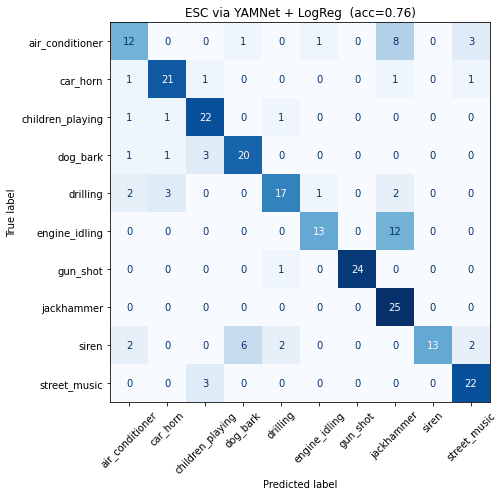

In [8]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=CLASSES,
    xticks_rotation=45, cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f'ESC via YAMNet + LogReg  (acc={acc:.2f})')
plt.tight_layout()
plt.show()

## 7. A few example predictions
Listen and see predicted vs true labels (audio playback is inline, nothing is saved).

In [9]:
from IPython.display import Audio, display

sample = test_df.sample(3, random_state=1)
for _, row in sample.iterrows():
    p = clip_path(row)
    emb = get_embedding(p).reshape(1, -1)
    pred = clf.predict(emb)[0]
    wav, _ = librosa.load(p, sr=SR, mono=True)
    print(f"TRUE: {row['class']:<18}  PRED: {pred}")
    display(Audio(wav, rate=SR))

TRUE: children_playing    PRED: children_playing


TRUE: street_music        PRED: street_music


TRUE: street_music        PRED: street_music


## Summary
In this demo, you saw:
1. **Transfer learning**: YAMNet embeddings + Logistic Regression, no training from scratch
2. **Evaluation**: held-out-fold accuracy + confusion matrix
### Key Takeaways

- A **frozen pretrained backbone + a linear head** gives a strong ESC baseline with almost
  no training and no GPU — the practical default when you have limited data.
- The confusion matrix shows the usual hard pairs (e.g. *jackhammer* vs *drilling*,
  *air_conditioner* vs *engine_idling*) — acoustically similar textures.
- Same YAMNet front-end is reused in **5-ASC** (mean-pooled scene embeddings) and
  **5-SED** (per-frame scores) — *same front-end, different head.*